<img src="logo-facty.jpeg" width="150" align="left"/>

<div style="text-align: center;">
    <h2><b>University of Carabobo</b></h2>
    <h3><b>Experimental Faculty of Sciences and Technology (FACYT)</b></h3>
    <h4><b>Computer Science Department</b></h4>
    <p style="text-align:center"><b>Course:</b> Machine Learning (Elective)<br>
    <b>Professor:</b> Álvaro Espinoza<br>
    <b>Date:</b> August 2026<br>
    <b>Students:</b> Juan Suárez and Josue Carrion</p>
</div>

<br clear="all">

---
# **StarCraft 2 Player Skill Prediction**
## **Exploratory Data Analysis (EDA)**

### **The Problem**
This notebook presents a comprehensive Exploratory Data Analysis (EDA) on the StarCraft 2 (SkillCraft) dataset. The primary objective is to evaluate data quality, identify missing values, and analyze telemetry and mechanical variables (such as APM, Action Latency, and PACs) to understand their relationship with the player's rank (`LeagueIndex`). 

---


**Domain and Motivation**

StarCraft 2 is a highly competitive Real-Time Strategy (RTS) game where players gather resources, build armies, and control units in real-time. In this domain, cognitive speed and mechanical execution are critical. The motivation of this project is to understand how a player's mechanical abilities (e.g., Actions Per Minute, Action Latency) and demographic traits relate to their competitive rank. This exploratory analysis will help identify which variables exhibit the strongest observed associations with skill, establishing an empirical foundation for a predictive Machine Learning model.

**Prediction Timestamp (Operational ML Formulation)**

* **Inference Moment:** The prediction is executed strictly **post-match**, immediately after a game concludes and its replay file (`.SC2Replay`) is processed by the telemetry extraction parser.
* **Prevention of Target Leakage / Lookahead Bias:** Under this post-match formulation, aggregated match-level telemetry metrics (such as average `APM`, mean `ActionLatency`, cumulative `TotalMapExplored`, and rate metrics like `WorkersMade` and `ComplexUnitsMade`) are fully available at the moment of prediction. These variables represent legitimate summary descriptors of the finished match and do not constitute temporal data leakage or future information.

**Unit of Observation and Independence Assumptions**

* **Unit of Observation:** A single player's performance during a specific recorded match (`GameID`).
* **Dataset Limitation (Absence of PlayerID):** The dataset does not provide an explicit player identifier (`PlayerID`). While verifying that `GameID` is unique confirms there are no duplicate game records, it **does not guarantee independent and identically distributed (I.I.D.) observations across rows at the player level**. A single player may have contributed multiple replays to the dataset.
* **Implication for Validation:** In the absence of a `PlayerID`, standard random or stratified splitting cannot group by player (*group splitting*). Consequently, there is an unavoidable risk of intra-player correlation across splits (*group leakage*), where a model might partially recognize individual playing habits. This constitutes an inherent constraint of the SkillCraft dataset that must be formally acknowledged.

**Target Variable and Problem Type**

* **Target Variable:** `LeagueIndex`
* **Meaning:** It represents the player's rank/league in the game, ranging from 1 (Bronze - lowest) to 8 (Professional - highest).
* **Problem Type:** This is a **Multiclass Classification** problem. Because the classes have a strict natural order (a higher index implies a higher skill level), it can also be approached as an **Ordinal Classification** problem.

### **Critical Questions**

To ensure a structured and goal-oriented exploration, this analysis will be guided by the following core questions:

* **Structural and Data Quality:** What are the analytical roles of the variables, and are there hidden missing values, unexpected string characters, or physically impossible outliers ?
* **Target Distribution:** How is the target variable (`LeagueIndex`) distributed, and is there a class imbalance that needs to be addressed or considered for a baseline model?
* **Feature Associations:** Which mechanical and telemetry variables exhibit the strongest correlation with the player's skill level? 
* **Multivariate Patterns:** How do early-game mechanics (like worker production) interact with attention metrics (PACs) across different leagues?
* **Feature Engineering:** Can we derive new metrics (e.g., action efficiency or attention span ratios) from the raw telemetry that might better separate low-tier players from experts?

### **Configuration**

In [1]:
# Standard Library
import warnings
import os
warnings.filterwarnings('ignore')

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Global Plot Settings
sns.set_theme(style='darkgrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#F8F9FA',
    'axes.facecolor': '#F8F9FA',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Reproducibility Seed
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# League Label Mapping
LEAGUE_LABELS = {
    1: 'Bronze',
    2: 'Silver',
    3: 'Gold',
    4: 'Platinum',
    5: 'Diamond',
    6: 'Master',
    7: 'GrandMaster',
    8: 'Professional'
}

# Create figures directory if needed
os.makedirs('figures', exist_ok=True)

print('Libraries loaded and global settings configured.')
print(f'   pandas  version: {pd.__version__}')
print(f'   numpy   version: {np.__version__}')
print(f'   seaborn version: {sns.__version__}')

Libraries loaded and global settings configured.
   pandas  version: 3.0.5
   numpy   version: 2.5.2
   seaborn version: 0.13.2


### **Dataset Loading**

In [2]:
#Dataset Path
DATA_PATH = '../data/SkillCraft1_Dataset.csv'

# Load dataset treating '?' as missing values at ingestion time
df= pd.read_csv(DATA_PATH, na_values=['?'])

print(f'Dataset loaded: {df.shape[0]:,} rows (data) x {df.shape[1]} columns(variables)')

Dataset loaded: 3,395 rows (data) x 20 columns(variables)


### **Data Dictionary — Column Descriptions**

The following table describes every column in the dataset, its type, and its domain meaning:

| Column | Type | Description |
|---|---|---|
| `GameID` | Identifier | Unique surrogate key that identifies each recorded game session. It carries no predictive information. |
| `LeagueIndex` | **Target** (Ordinal) | Player's competitive league rank: **1** = Bronze, **2** = Silver, **3** = Gold, **4** = Platinum, **5** = Diamond, **6** = Master, **7** = GrandMaster, **8** = Professional. Higher = better. |
| `Age` | Demographic | Self-reported age of the player in years. Contains hidden missing values encoded as `?`. |
| `HoursPerWeek` | Demographic | Average number of hours the player dedicates to StarCraft per week. Contains `?` nulls and physically impossible values (> 168 h). |
| `TotalHours` | Demographic | Total lifetime hours the player has accumulated in StarCraft. Contains `?` nulls and at least one extreme outlier (~1,000,000 h). |
| `APM` | Telemetry – Pace | **Actions Per Minute** — total number of distinct keyboard/mouse commands issued per minute. The most classic proxy for mechanical speed in RTS games. |
| `SelectByHotkeys` | Telemetry – Hotkeys | Rate of unit-group selections performed via hotkeys (per timestamp). Measures how efficiently the player uses keyboard shortcuts for selection. |
| `AssignToHotkeys` | Telemetry – Hotkeys | Rate of unit-group assignments to hotkey slots. Higher values indicate a more structured control-group setup. |
| `UniqueHotkeys` | Telemetry – Hotkeys | Number of distinct hotkey slots actively used during the game. Experts typically use more unique hotkeys simultaneously. |
| `MinimapAttacks` | Telemetry – Attention | Rate of attack orders issued directly on the minimap (per timestamp). Signals macro-level map aggression without switching camera. |
| `MinimapRightClicks` | Telemetry – Attention | Rate of movement commands issued on the minimap. Higher values indicate better macro management and global army positioning. |
| `NumberOfPACs` | Telemetry – Attention | **Perception-Action Cycles per minute** — a PAC is defined as a camera movement followed by an action. Reflects how often the player shifts attention to a new area. |
| `GapBetweenPACs` | Telemetry – Attention | Average time gap (in milliseconds) between consecutive PACs. Smaller gaps indicate faster context-switching and higher multitasking ability. |
| `ActionLatency` | Telemetry – Pace | Average time (in milliseconds) between a camera movement and the first subsequent action. A low latency means the player acts quickly upon arriving at a new screen location. |
| `ActionsInPAC` | Telemetry – Pace | Average number of actions executed within a single PAC. More actions per PAC suggests more efficient attention cycles. |
| `TotalMapExplored` | Telemetry – Units/Map | Proportion of the map revealed by the player over the course of the game. Higher exploration generally correlates with better map awareness. |
| `WorkersMade` | Telemetry – Units/Map | Rate of worker units produced (per timestamp). Consistent worker production is a fundamental macro-economy skill in StarCraft. |
| `UniqueUnitsMade` | Telemetry – Units/Map | Rate reflecting the variety of unit types produced. A diverse army composition often indicates strategic flexibility. |
| `ComplexUnitsMade` | Telemetry – Units/Map | Rate of advanced/complex units produced (units that require more resources or tech). Signals late-game strategic depth. |
| `ComplexAbilitiesUsed` | Telemetry – Units/Map | Rate of complex unit abilities activated (e.g., special spells or micro-intensive commands). High usage separates mechanically skilled players from average ones. |

### **Structural Inspection and Analytical Roles**

Before any analysis, we must understand the *structure* of the dataset: the data types, memory footprint, and the **analytical role** each column plays in the prediction task.

In [3]:
# 1. Check for completely duplicated rows
duplicates = df.duplicated().sum()
print(f"Total duplicated rows: {duplicates}")

# 2. Fix Data Type Discrepancies (Unmasking hidden nulls)
# The variables 'Age', 'HoursPerWeek', and 'TotalHours' contain non-numeric string characters (like '?').
# We force the conversion to numeric; invalid parsing will be set as NaN.
problematic_cols = ['Age', 'HoursPerWeek', 'TotalHours']

for col in problematic_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nData types successfully converted. Hidden string characters are now genuine NaNs.")

Total duplicated rows: 0

Data types successfully converted. Hidden string characters are now genuine NaNs.


In [4]:
# Calculate absolute and percentage of missing values
missing_data = df.isnull().sum()
missing_data = missing_data[missing_data > 0]

missing_percentage = (missing_data / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_data,
    'Percentage (%)': missing_percentage
}).sort_values(by='Percentage (%)', ascending=False)

print("Missing Values Summary:")
print(missing_df)

Missing Values Summary:
              Missing Values  Percentage (%)
TotalHours                57        1.678940
HoursPerWeek              56        1.649485
Age                       55        1.620029


In [5]:
# Exploratory check for impossible ranges
# We use describe() to inspect the min and max values of our newly converted numeric columns.
demographic_summary = df[['Age', 'HoursPerWeek', 'TotalHours']].describe()
print("Summary Statistics for Demographic Variables:")
print(demographic_summary.loc[['min', 'max', 'mean']])

Summary Statistics for Demographic Variables:
            Age  HoursPerWeek      TotalHours
min   16.000000      0.000000        3.000000
max   44.000000    168.000000  1000000.000000
mean  21.647904     15.910752      960.421809


In [6]:
# Exploratory check for mechanical/telemetry variables
# We verify that system-generated metrics do not contain impossible system errors
mechanical_cols = df.columns.drop(['GameID', 'LeagueIndex', 'Age', 'HoursPerWeek', 'TotalHours'])
mechanical_summary = df[mechanical_cols].describe().loc[['min', 'max']]

print("\nSummary Statistics for Mechanical Variables (Min and Max):")
print(mechanical_summary)


Summary Statistics for Mechanical Variables (Min and Max):
          APM  SelectByHotkeys  AssignToHotkeys  UniqueHotkeys  \
min   22.0596         0.000000         0.000000            0.0   
max  389.8314         0.043088         0.001752           10.0   

     MinimapAttacks  MinimapRightClicks  NumberOfPACs  GapBetweenPACs  \
min        0.000000            0.000000      0.000679          6.6667   
max        0.003019            0.004041      0.007971        237.1429   

     ActionLatency  ActionsInPAC  TotalMapExplored  WorkersMade  \
min        24.0936        2.0389               5.0     0.000077   
max       176.3721       18.5581              58.0     0.005149   

     UniqueUnitsMade  ComplexUnitsMade  ComplexAbilitiesUsed  
min              2.0          0.000000              0.000000  
max             13.0          0.000902              0.003084  


In [7]:
# Check for physically impossible or extreme values in demographic data
extreme_total_hours = df[df['TotalHours'] > 50000] # More than ~5.7 years playing 24/7
extreme_weekly_hours = df[df['HoursPerWeek'] >= 168] # 168 hours is the total hours in a week

print(f"\nPlayers with physically impossible TotalHours (>50,000): {len(extreme_total_hours)}")
if len(extreme_total_hours) > 0:
    print(f"Max TotalHours found: {extreme_total_hours['TotalHours'].max()}")

print(f"\nPlayers with impossible HoursPerWeek (>=168): {len(extreme_weekly_hours)}")


Players with physically impossible TotalHours (>50,000): 1
Max TotalHours found: 1000000.0

Players with impossible HoursPerWeek (>=168): 1


#### **Missing Data Pattern Analysis (Structured Missingness Across Leagues)**
Before applying any imputation or deletion, we must evaluate how missing values are distributed across our target classes (`LeagueIndex`). If missingness is structurally concentrated in a specific tier, global deletion strategies (such as `dropna()`) will inadvertently eradicate entire categories and destroy critical predictive signal.

In [8]:
# Analyze the nulls values distribution for all demographic variables
total_por_liga = df.groupby('LeagueIndex').size()

# Counting null values per league
missing_age = df[df['Age'].isna()].groupby('LeagueIndex').size().reindex(total_por_liga.index, fill_value=0)
missing_hours = df[df['HoursPerWeek'].isna()].groupby('LeagueIndex').size().reindex(total_por_liga.index, fill_value=0)
missing_total_hours = df[df['TotalHours'].isna()].groupby('LeagueIndex').size().reindex(total_por_liga.index, fill_value=0)

# Building the comparative dataframe
missing_by_league = pd.DataFrame({
    'Total Players': total_por_liga,
    'Missing Age': missing_age,
    'Missing HoursPerWeek': missing_hours,
    'Missing TotalHours': missing_total_hours
})

# Calculate percentage of missing values per league
missing_by_league['% Age NaN'] = (missing_by_league['Missing Age'] / missing_by_league['Total Players']) * 100
missing_by_league['% Hours/W NaN'] = (missing_by_league['Missing HoursPerWeek'] / missing_by_league['Total Players']) * 100
missing_by_league['% TotalH NaN'] = (missing_by_league['Missing TotalHours'] / missing_by_league['Total Players']) * 100

print("--- Demographic Missingness Pattern by League ---")
display(missing_by_league[['Total Players', '% Age NaN', '% Hours/W NaN', '% TotalH NaN']].sort_index())

--- Demographic Missingness Pattern by League ---


,Total Players,% Age NaN,% Hours/W NaN,% TotalH NaN
LeagueIndex,,,,
1,167,0.0,0.000000,0.000000
2,347,0.0,0.000000,0.000000
3,553,0.0,0.000000,0.000000
4,811,0.0,0.000000,0.000000
5,806,0.0,0.124069,0.248139
6,621,0.0,0.000000,0.000000
7,35,0.0,0.000000,0.000000
8,55,100.0,100.000000,100.000000


## **Data Quality Synthesis and Action Plan**

**Critical finding (Structured Missingness in League 8):** The missing data analysis reveals a severe structural pattern: exactly 100% of Professional players (League 8) lack demographic data (`Age`, `TotalHours`, `HoursPerWeek`), whereas amateur leagues present virtually complete demographic records (< 0.25% missing). This concentration demonstrates that the absence is structured and deterministically conditioned on the target variable. While this is compatible with a Missing Not At Random (MNAR) mechanism or with an intentional anonymization decision applied to professional e-sports athletes during dataset collection, the exact generating mechanism cannot be proven solely from the observational dataset. It must therefore be formulated as a plausible domain hypothesis.

### **Action Plan:**

To maintain the integrity of the dataset and preserve the critical predictive signal of the elite class, we implement the following data preprocessing strategy:

**1. Preservation of Structured Nulls (Preventing Class Eradication):**
We strictly prohibit global drop operations (e.g., `df.dropna()`). Removing rows based on missing demographic values would lead to the complete eradication of League 8 from the dataset, irreversibly destroying the mechanical telemetry associated with the game's highest skill ceiling (55 observations).

**2. Conditional Filtering of Physical Outliers:**
We proceed to filter the physically impossible demographic data entry errors identified earlier (e.g., `TotalHours` > 50,000 or `HoursPerWeek` >= 168). However, this is executed using a targeted logical condition that explicitly retains `NaN` values (`| df['column'].isna()`). This guarantees the removal of invalid data without jeopardizing unrecorded professional players.

**3. Deferred Modeling Strategy for Missing Data (Leakage Prevention):**
Because the missing demographic values are perfectly aligned with League 8, allowing an algorithm to exploit missingness directly (e.g., via native NaN branching or missingness indicator flags) would introduce severe **Target Leakage**—enabling the model to classify professionals based on an observational artifact rather than true in-game telemetry. Therefore, in the subsequent pipeline, missing demographic values will be imputed using median statistics learned strictly on the training folds.

In [9]:
# Store original size for comparison
original_size = len(df)

# 1. Create a clean copy WITHOUT dropping NaNs to protect League 8
df_clean = df.copy()

# 2. Filter out logically impossible demographic outliers while explicitly keeping NaNs
df_clean = df_clean[(df_clean['TotalHours'] < 50000) | (df_clean['TotalHours'].isna())]
df_clean = df_clean[(df_clean['HoursPerWeek'] < 168) | (df_clean['HoursPerWeek'].isna())]

# Calculate final dataset size and data loss percentage
final_size = len(df_clean)
rows_dropped = original_size - final_size

print("--- Data Cleaning Summary ---")
print(f"Original dataset size: {original_size} rows")
print(f"Cleaned dataset size:  {final_size} rows")
print(f"Total rows dropped:    {rows_dropped} rows (Physical outliers only)")
print(f"League 8 players retained: {df_clean[df_clean['LeagueIndex'] == 8].shape[0]}")

# 3. Explicit Target Distribution Audit (Before vs. After Cleaning)
before_counts = df['LeagueIndex'].value_counts().sort_index()
after_counts = df_clean['LeagueIndex'].value_counts().sort_index()
audit_df = pd.concat([before_counts, after_counts, (after_counts - before_counts)], axis=1)
audit_df.columns = ['Before', 'After', 'Difference']
print("\n--- Target Distribution Audit by League ---")
display(audit_df)

--- Data Cleaning Summary ---
Original dataset size: 3395 rows
Cleaned dataset size:  3393 rows
Total rows dropped:    2 rows (Physical outliers only)
League 8 players retained: 55

--- Target Distribution Audit by League ---


,Before,After,Difference
LeagueIndex,,,
1,167,167,0
2,347,347,0
3,553,553,0
4,811,811,0
5,806,805,-1
6,621,620,-1
7,35,35,0
8,55,55,0


### **Univariate Analysis**

In this section, we analyze the individual distributions of key numerical variables (both demographic and mechanical) to understand their central tendency, dispersion, shape, skewness, and extreme values. We will utilize histograms with Kernel Density Estimates (KDE) to visualize the shape, and boxplots to clearly identify outliers and dispersion.

Variables with highest right-skewness:
TotalHours              14.539652
MinimapAttacks           4.818589
ComplexAbilitiesUsed     3.781329
SelectByHotkeys          2.976696
MinimapRightClicks       2.563080
ComplexUnitsMade         2.304426
dtype: float64


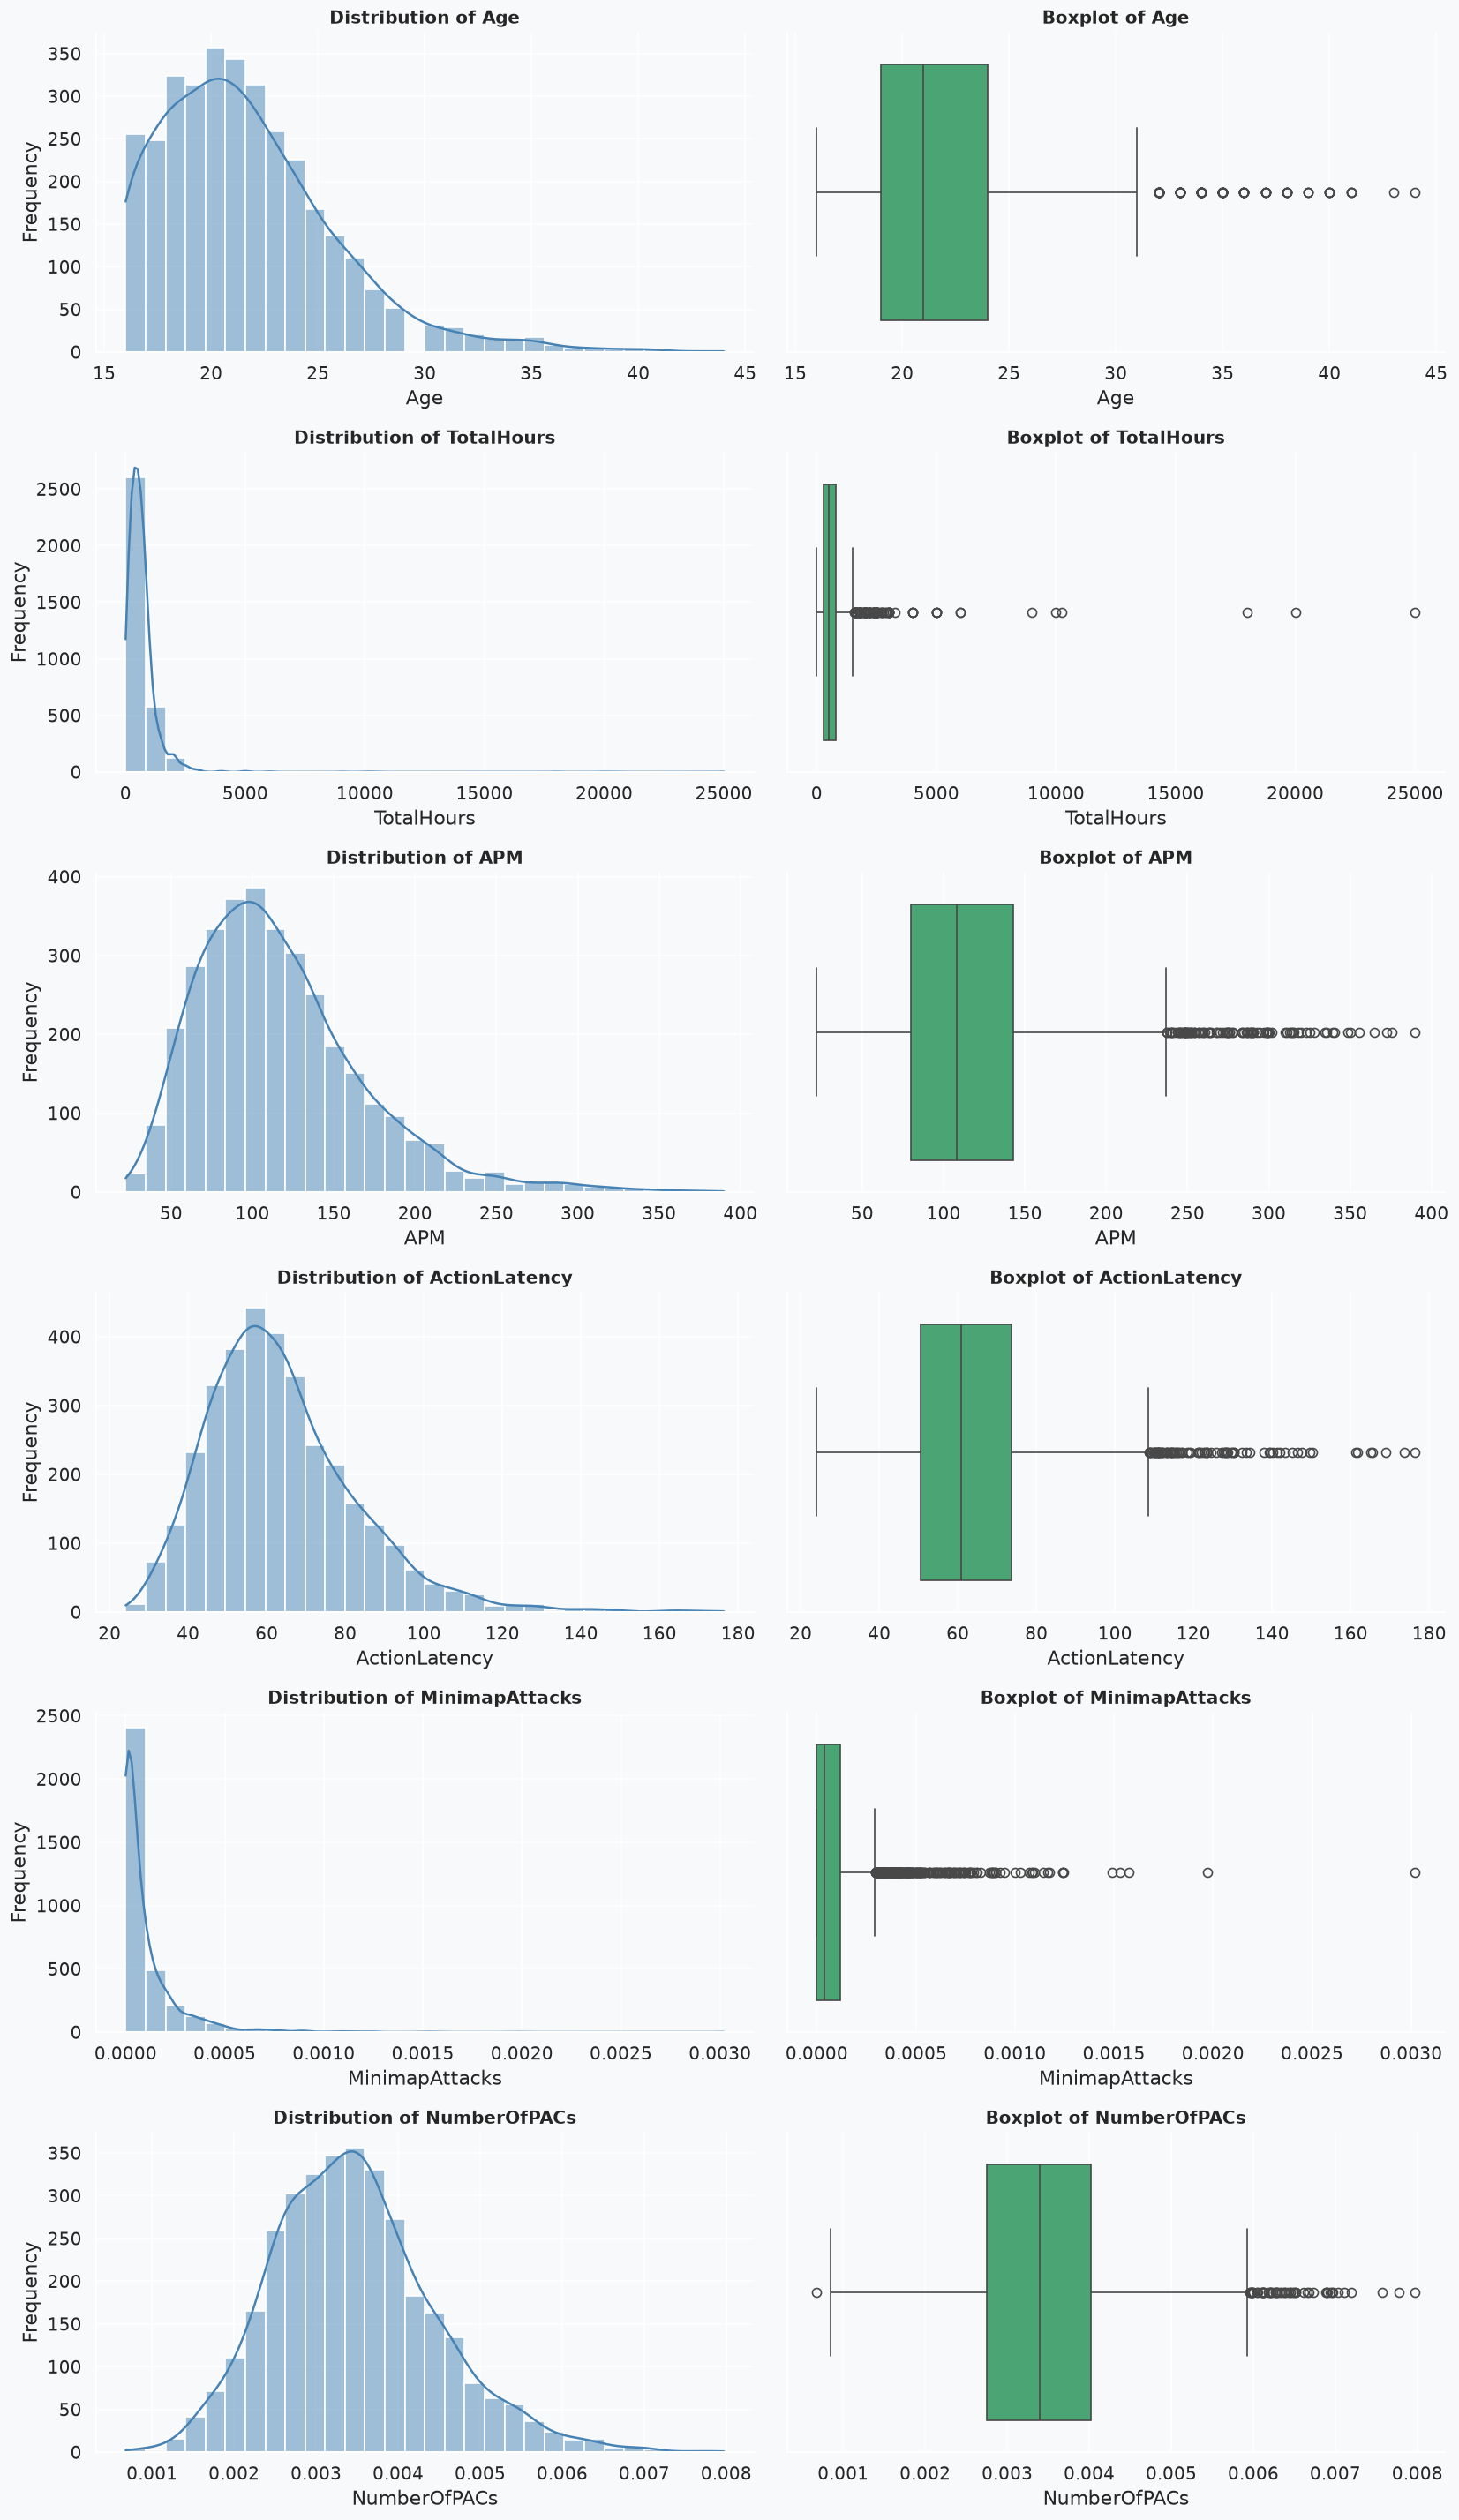

Descriptive Statistics for Key Variables:


,Age,TotalHours,APM,ActionLatency,MinimapAttacks,NumberOfPACs
count,3338.000000,3336.000000,3393.000000,3393.000000,3393.000000,3393.000000
mean,21.650689,660.859712,116.964237,63.754857,0.000098,0.003462
std,4.205990,856.414364,51.845413,19.233971,0.000166,0.000992
min,16.000000,3.000000,22.059600,24.093600,0.000000,0.000679
25%,19.000000,300.000000,79.827000,50.454900,0.000000,0.002753
50%,21.000000,500.000000,108.002400,60.938900,0.000040,0.003395
75%,24.000000,800.000000,142.767000,73.698300,0.000119,0.004025
max,44.000000,25000.000000,389.831400,176.372100,0.003019,0.007971


In [10]:
# Calculate skewness for all numeric features to detect long tails mathematically
numeric_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
skewness_vals = df_clean[numeric_cols].skew().sort_values(ascending=False)

print("Variables with highest right-skewness:")
print(skewness_vals.head(6))
# Select a representative subset of continuous variables for analysis
key_vars = ['Age', 'TotalHours', 'APM', 'ActionLatency', 'MinimapAttacks', 'NumberOfPACs']

# Create a figure with subplots (6 rows, 2 columns)
fig, axes = plt.subplots(nrows=len(key_vars), ncols=2, figsize=(14, 24))

for i, var in enumerate(key_vars):
    # Histogram with KDE (to observe shape, center, and skewness)
    sns.histplot(data=df_clean, x=var, kde=True, ax=axes[i, 0], color='steelblue', bins=30)
    axes[i, 0].set_title(f'Distribution of {var}', fontsize=12, fontweight='bold')
    axes[i, 0].set_ylabel('Frequency')
    
    # Boxplot (to observe dispersion and extreme values)
    sns.boxplot(data=df_clean, x=var, ax=axes[i, 1], color='mediumseagreen')
    axes[i, 1].set_title(f'Boxplot of {var}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Display the descriptive statistics for these specific variables
print("Descriptive Statistics for Key Variables:")
display(df_clean[key_vars].describe())

#### **Univariate Analysis Conclusions**

Based on the visual and statistical evidence, we conclude the following regarding key feature distributions:

* **Skewness and Extreme Tails:** Following the removal of physically impossible values (> 50,000 h), the mathematical skewness of `TotalHours` is approximately **14.54** (down from > 50 in the raw data). In-game action rates such as `MinimapAttacks` also exhibit pronounced right-skewness (~4.82). These substantial positive tails can disproportionately influence linear algorithms. **Recommendation for Data Prep:** Apply logarithmic transformations (`log1p`) or power transforms to compress extreme tails and stabilize variance.
* **Demographic Variables (`Age` and `TotalHours`) Note:** As reflected in the descriptive statistics (`Age` count = 3,338; `TotalHours` count = 3,336 vs. 3,393 total rows), demographic features intentionally retain missing values for all 55 professional players (League 8) and a handful in League 5. Consequently, **summary statistics for Age and TotalHours describe amateur tiers only and do not reflect professional players**. Among amateurs, player age is right-skewed with a median of 21 years (75th percentile = 24), with players over 30 appearing as upper statistical outliers.
* **APM (Actions Per Minute):** Displays a moderately right-skewed, near-normal distribution with a median of ~108 APM. The upper tail extends past 250 APM and reaches up to 389.8 APM; as established in data validation, these values reflect the valid physical capacity and rapid keystroke mechanics of elite competitors rather than erroneous measurements.
* **ActionLatency:** Positively skewed with a median of approximately **61 milliseconds (ms)** (defined strictly in milliseconds per the SkillCraft study). Lower values signify superior performance (faster reaction time). The right-side tail captures players requiring substantial latency to initiate actions following perception-action shifts.
* **NumberOfPACs:** Fairly symmetric and bell-shaped with a mean around 0.0034 PACs per timestamp, indicating that visual attentional switching rates follow an approximately Gaussian distribution across the player population.

### **Target Variable Analysis**

The target variable for our future predictive model is `LeagueIndex`. It is an ordinal categorical variable representing the player's competitive rank. The values map to the official StarCraft 2 leagues:
1. Bronze
2. Silver
3. Gold
4. Platinum
5. Diamond
6. Master
7. GrandMaster
8. Professional (E-sports players)

In this section, we analyze the distribution of these classes to determine if the dataset is imbalanced and to establish a naive baseline accuracy for future modeling.

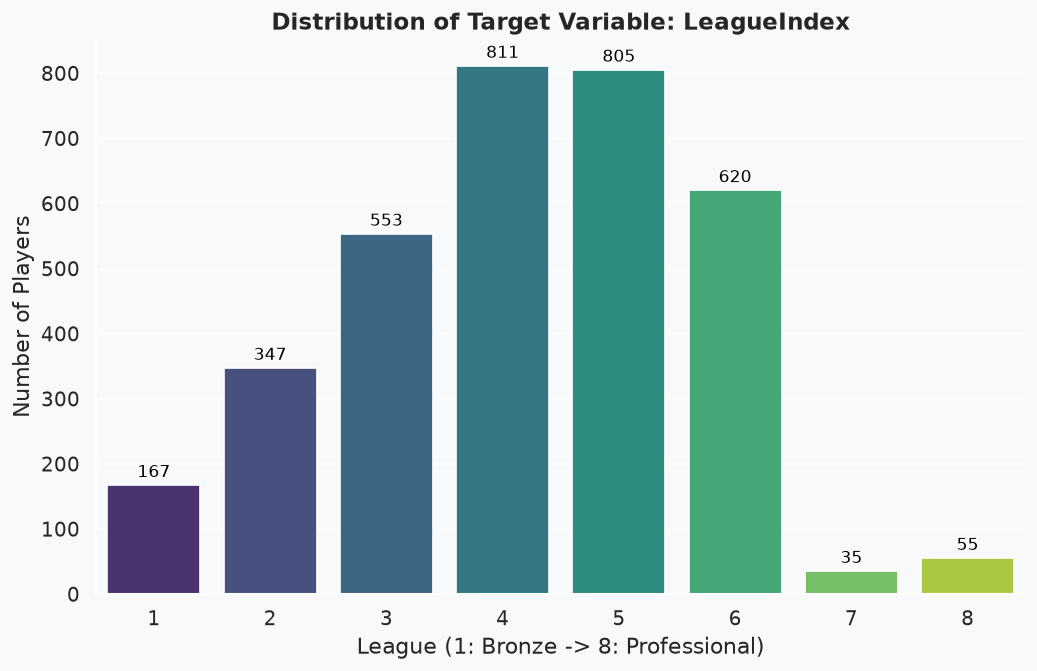

--- Target Variable Proportions ---
LeagueIndex
4     23.9 %
5    23.73 %
6    18.27 %
3     16.3 %
2    10.23 %
1     4.92 %
8     1.62 %
7     1.03 %
Name: proportion, dtype: str

--- Naive Baseline ---
Majority Class: League 4
Baseline Accuracy: 23.90%


In [11]:
# Create a figure for the target variable distribution
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df_clean, x='LeagueIndex', palette='viridis')

# Add exact counts on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='baseline', 
                fontsize=10, color='black', xytext=(0, 5), 
                textcoords='offset points')

plt.title('Distribution of Target Variable: LeagueIndex', fontsize=14, fontweight='bold')
plt.ylabel('Number of Players')
plt.xlabel('League (1: Bronze -> 8: Professional)')
plt.show()

# Calculate proportions and Baseline
class_counts = df_clean['LeagueIndex'].value_counts()
class_proportions = df_clean['LeagueIndex'].value_counts(normalize=True) * 100

majority_class = class_counts.idxmax()
baseline_accuracy = class_proportions.max()

print("--- Target Variable Proportions ---")
print(class_proportions.round(2).astype(str) + ' %')
print("\n--- Naive Baseline ---")
print(f"Majority Class: League {majority_class}")
print(f"Baseline Accuracy: {baseline_accuracy:.2f}%")

#### **Target Variable Conclusions**

* **Distribution and Balance:** The target variable follows a roughly normal (bell-shaped) distribution, which naturally reflects the skill distribution in competitive games. The middle leagues (Platinum 4, Diamond 5, and Master 6) contain the majority of the player base. 
* **Class Imbalance:** The dataset is imbalanced at the extremes. There are very few players in League 1 (Bronze: 4.92%) and League 8 (Professional: 1.62%). This imbalance is structural to the competitive ladder, not a data collection error, but it indicates that a future model might struggle to correctly classify the minority classes at the extreme ends.
* **Naive Baseline:** The most frequent class is League 4 (Platinum), accounting for 811 of the 3,393 cleaned observations. Therefore, a naive majority-class classifier that predicts "League 4" for every player achieves a baseline accuracy of **23.90%** (811 / 3,393).

### **Bivariate and Multivariate Analysis**

In this section, we explore the relationships between our features and the target variable (`LeagueIndex`), as well as the correlations among the predictors themselves. The goal is to identify strong predictive patterns, detect feature redundancy (multicollinearity), and explore multivariate interactions, while maintaining the statistical principle that association does not imply causality.

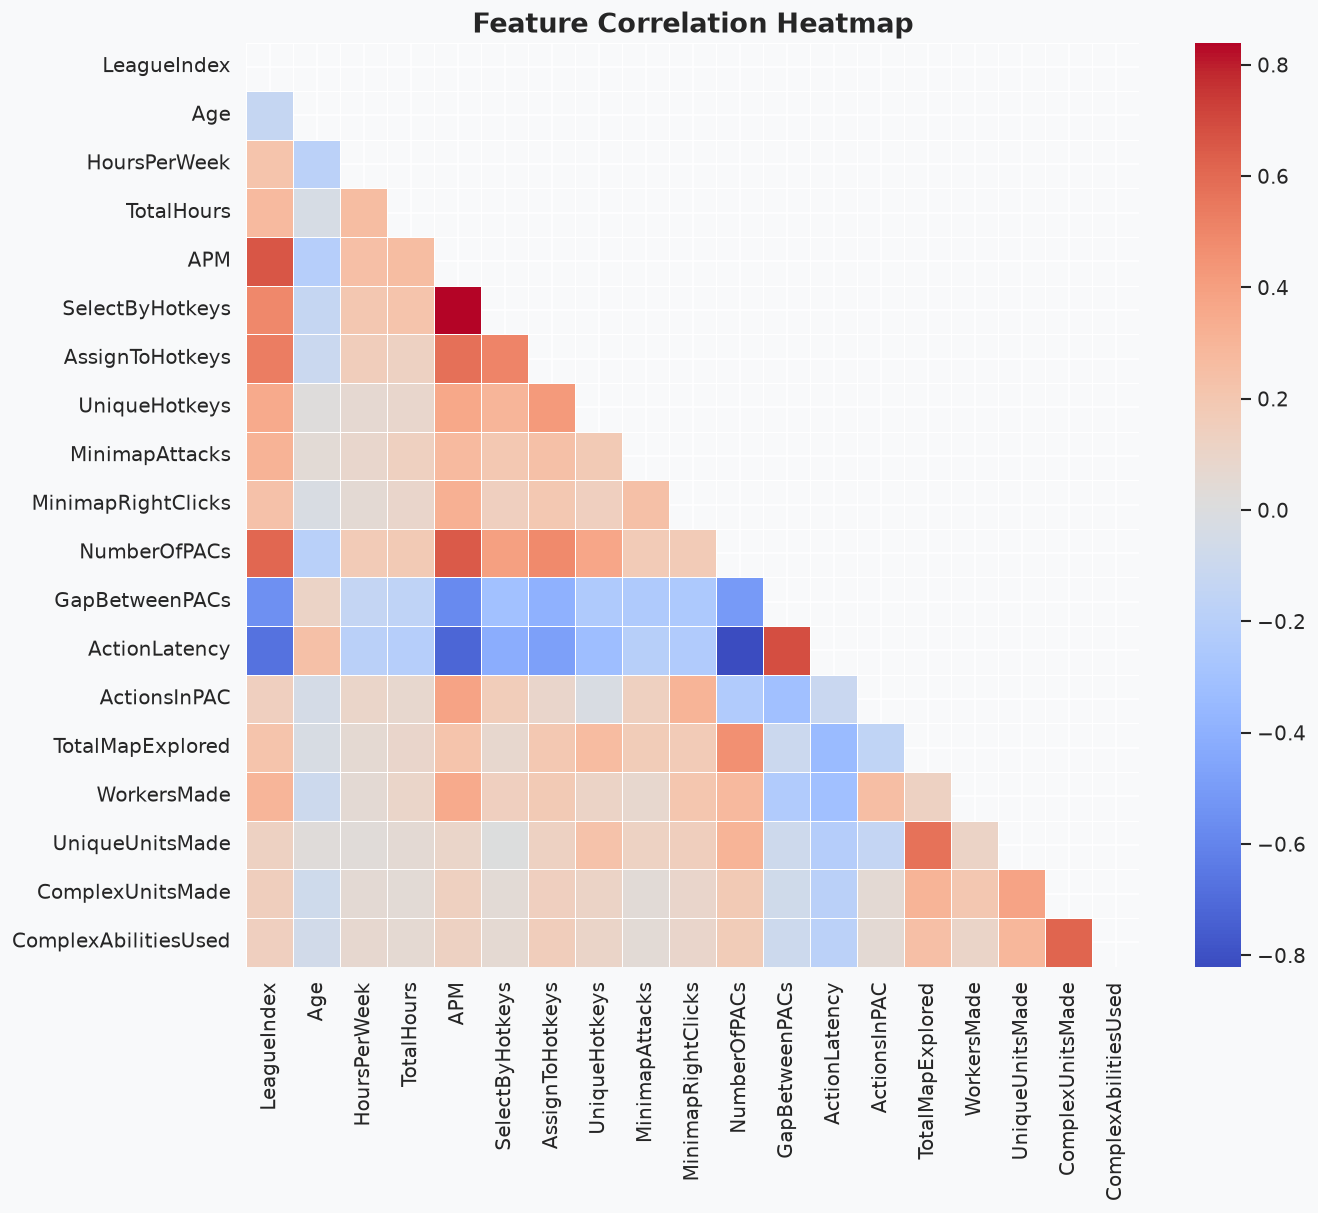

--- Top Correlations with LeagueIndex ---

Strongest Positive Correlations:
LeagueIndex        1.000000
APM                0.662654
NumberOfPACs       0.611999
AssignToHotkeys    0.530871
Name: LeagueIndex, dtype: float64

Strongest Negative Correlations:
Age              -0.127233
GapBetweenPACs   -0.553071
ActionLatency    -0.673797
Name: LeagueIndex, dtype: float64


In [12]:
# Remove the non-predictive identifier before running correlations
corr_df = df_clean.drop(columns=['GameID'])

# Calculate the Pearson correlation matrix
corr_matrix = corr_df.corr()

# Plot the heatmap
plt.figure(figsize=(12, 10))
# Create a mask to hide the upper triangle to make it less visually overwhelming
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', annot=False, fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.show()

# Extract and display the top correlations specifically with the target variable
print("--- Top Correlations with LeagueIndex ---")
target_corr = corr_matrix['LeagueIndex'].sort_values(ascending=False)
print("\nStrongest Positive Correlations:")
print(target_corr.head(4))
print("\nStrongest Negative Correlations:")
print(target_corr.tail(3))

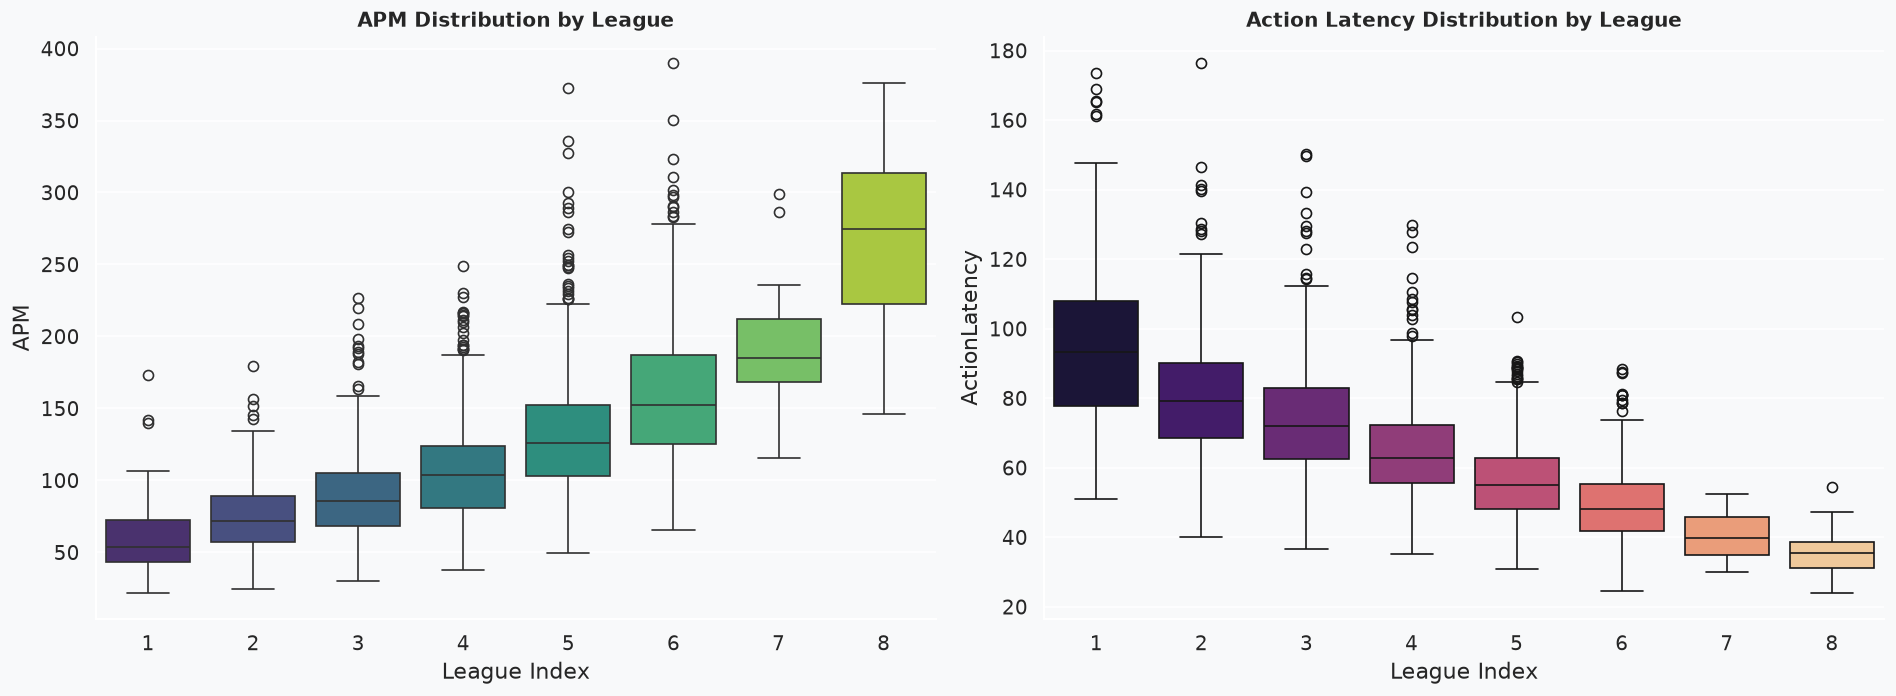

In [13]:
# Compare key distributions across the target classes (Leagues)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# APM vs LeagueIndex
sns.boxplot(data=df_clean, x='LeagueIndex', y='APM', ax=axes[0], palette='viridis')
axes[0].set_title('APM Distribution by League', fontsize=12, fontweight='bold')
axes[0].set_xlabel('League Index')

# ActionLatency vs LeagueIndex
sns.boxplot(data=df_clean, x='LeagueIndex', y='ActionLatency', ax=axes[1], palette='magma')
axes[1].set_title('Action Latency Distribution by League', fontsize=12, fontweight='bold')
axes[1].set_xlabel('League Index')

plt.tight_layout()
plt.show()

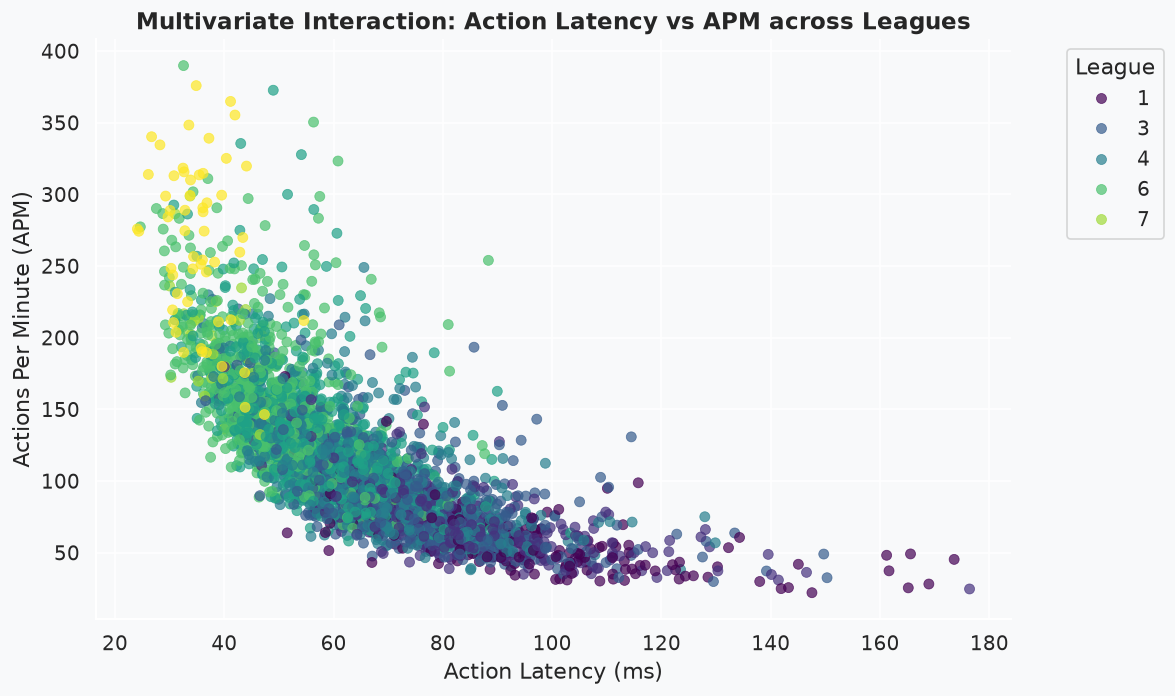

In [14]:
# Multivariate Interaction: APM vs ActionLatency, segmented by LeagueIndex
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='ActionLatency', y='APM', hue='LeagueIndex', 
                palette='viridis', alpha=0.7, edgecolor=None)
plt.title('Multivariate Interaction: Action Latency vs APM across Leagues', fontsize=14, fontweight='bold')
plt.xlabel('Action Latency (ms)')
plt.ylabel('Actions Per Minute (APM)')
plt.legend(title='League', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### **Bivariate and Multivariate Conclusions**

Based on the correlational and visual evidence, we conclude the following:

* **Strongest Target Associations:** Among all explored features, `ActionLatency` ($r = -0.67$), `APM` ($r = 0.66$), and `NumberOfPACs` ($r = 0.61$) exhibit the strongest observed linear bivariate associations with `LeagueIndex`. Higher competitive rank is characterized by reduced cognitive latency and increased mechanical pace.
* **Feature Redundancy (Multicollinearity):** A pronounced inverse correlation ($r = -0.72$) exists between `APM` and `ActionLatency`. Mechanically faster players inherently require less time to react. This collinearity is a redundancy that must be considered, as linear models can suffer from variance inflation when assigning independent weights to these features.
* **Multivariate Interaction:** The scatter plot reveals a clear diagonal clustering. Elite players (higher leagues, lighter colors) are exclusively clustered in the top-left quadrant (High APM, Low Latency). Meanwhile, lower-tier players spread out towards the bottom-right.
* **Sample Size Precaution:** As observed in the target variable distribution, Leagues 1, 7, and 8 have small sample sizes compared to the middle tiers. Distributional summaries in these specific groups (particularly boxplot whiskers) should be interpreted with awareness of sample variance.
* **Association vs. Causality Disclaimer:** Correlation does not imply causality. Forcing a player to click faster (artificially inflating APM) will not automatically grant them the strategic depth required to reach League 8. These telemetry variables are *indicators* or behavioral symptoms of underlying skill, not the sole mechanical cause of victory.

### **Feature Engineering**

Based on bivariate analysis, a pronounced negative correlation ($r = -0.72$) exists between `APM` (action pace) and `ActionLatency` (cognitive reaction time). To explore whether combining both dimensions can produce a parsimonious composite indicator, we formulate a candidate feature: the **Cognitive Speed Index (CSI)**:

$$\text{CSI} = \frac{\text{APM}}{\text{ActionLatency} + 1}$$

Because higher skill correlates with elevated APM and lower latency, the ratio is hypothesized to capture the joint cognitive-motor efficiency of the player. Importantly, constructing this ratio does not automatically solve multicollinearity; if raw features and the ratio are retained together, collinearity may in fact increase. Hence, the CSI is introduced here strictly as an engineered candidate feature whose utility will be empirically validated during the modeling stage.

Correlation of CognitiveSpeedIndex with LeagueIndex: 0.6594


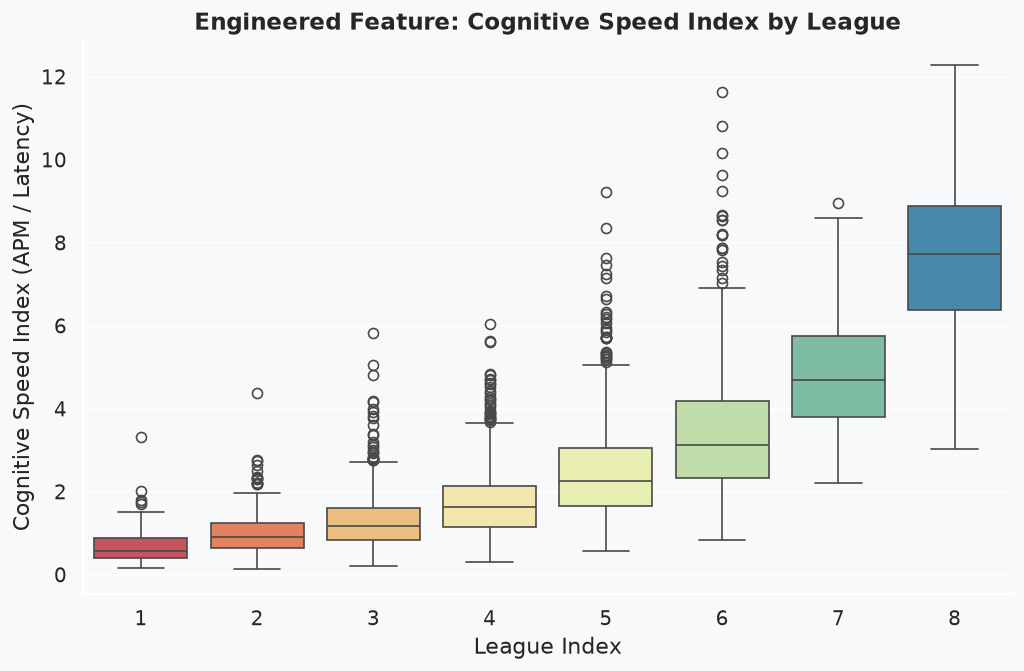

In [15]:
# 1. Create the new composite feature
# Adding a small constant to the denominator to prevent division by zero, just in case.
df_clean['CognitiveSpeedIndex'] = df_clean['APM'] / (df_clean['ActionLatency'] + 1)

# 2. Check the correlation of the new feature with the target variable
new_corr = df_clean[['CognitiveSpeedIndex', 'LeagueIndex']].corr().iloc[0,1]
print(f"Correlation of CognitiveSpeedIndex with LeagueIndex: {new_corr:.4f}")

# 3. Visualize the new feature's distribution across leagues
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='LeagueIndex', y='CognitiveSpeedIndex', palette='Spectral')
plt.title('Engineered Feature: Cognitive Speed Index by League', fontsize=14, fontweight='bold')
plt.xlabel('League Index')
plt.ylabel('Cognitive Speed Index (APM / Latency)')
plt.show()

#### **Feature Engineering Conclusions**

* **Observed Association vs. Raw Features:** The candidate feature `CognitiveSpeedIndex` exhibits a strong linear correlation with `LeagueIndex` ($r = 0.6594$). However, its individual bivariate association does not surpass that of the individual raw features (`ActionLatency` at $r = -0.6738$, `APM` at $r = 0.6627$). 
* **Class Separation:** The boxplot shows progressive upward separation across leagues, particularly differentiating elite tiers (Leagues 6, 7, and 8) from novice tiers. We refrain from terming this separation "exponential", as it represents an empirical distributional shift rather than a mathematically proven exponential function.
* **Multicollinearity and Modeling Protocol:** Defining a non-linear ratio of two correlated features does not inherently eliminate multicollinearity. Retaining all three features simultaneously (`APM`, `ActionLatency`, `CSI`) would introduce structural collinearity into linear models. Therefore, the true value of `CognitiveSpeedIndex` must be resolved during the modeling stage through out-of-sample cross-validation, explicitly benchmarking three model variants under identical validation splits:
  1. **Model A (Raw Features):** `APM` + `ActionLatency`
  2. **Model B (Single Ratio):** `CognitiveSpeedIndex` (excluding raw APM and Latency)
  3. **Model C (Combined):** `APM` + `ActionLatency` + `CognitiveSpeedIndex`

### **General Conclusions and Next Steps**

This Exploratory Data Analysis provides a comprehensive understanding of the StarCraft 2 telemetry dataset, establishing a solid foundation for the subsequent Machine Learning phase. The key findings and analytical decisions are summarized below:

**1. Data Quality and Preprocessing Strategy:**
*   The dataset contained a small fraction (< 2%) of missing values disguised as string characters in demographic features (`Age`, `HoursPerWeek`, `TotalHours`). These were converted to genuine NaNs and retained for targeted post-split imputation, as dropping them would completely eradicate the elite Professional tier (League 8, n=55).
*   Deterministic, physically impossible outliers were removed (2 rows with `TotalHours` > 50,000 or `HoursPerWeek` >= 168), reducing `TotalHours` skewness from > 50 to ~14.54 while preserving all 55 observations of League 8. All statistical imputation and scaling are strictly deferred to after the train/test split to prevent Data Leakage.
*   Mechanical variables exhibit extreme values that were purposely preserved, as domain validation confirms they represent the legitimate mechanical ceiling of elite competitors.

**2. Observed Associations and Feature Relationships:**
*   **Mechanical Dominance:** In-game telemetry, particularly `ActionLatency` ($r = -0.67$) and `APM` ($r = 0.66$), exhibited the strongest observed linear associations with `LeagueIndex`. Demographic variables like `Age` ($r = -0.13$) showed markedly weaker linear relationships.
*   **Multicollinearity and Candidate Feature:** A strong inverse relationship exists between `APM` and `ActionLatency` ($r = -0.72$). The `CognitiveSpeedIndex` (CSI) was engineered as a candidate composite metric ($r = 0.659$). Its true capability to mitigate multicollinearity without loss of predictive power will be benchmarked experimentally during modeling against the raw features.

**3. Target Variable, Prediction Timing, and Modeling Protocol:**
*   **Prediction Timing:** Confirmed as post-match replay telemetry analysis, validating the availability of all cumulative metrics at inference time without lookahead bias.
*   **Independence Limitation:** The dataset lacks a `PlayerID`, creating an unavoidable potential for intra-player correlation across train/test splits.
*   **Class Imbalance & Naive Baseline:** The target variable `LeagueIndex` presents severe scarcity at the extremes (Leagues 1, 7, and 8). The majority class is League 4 (Platinum), establishing a naive baseline accuracy of **23.90%** (811 / 3,393). Stratified sampling will be strictly enforced during validation to preserve class proportions.

### **Feature Inventory — Synthesis for Data Preparation**

To ensure seamless traceability between this Exploratory Data Analysis and the subsequent Data Preparation pipeline, the complete set of features is cataloged below with their analytical roles, data quality characteristics, and recommended engineering transformations:

| Feature Name | Data Type | Domain Category | Missingness Status | Distribution / Skewness | Recommended Pipeline Action |
|---|---|---|---|---|---|
| `GameID` | Integer | Identifier | None (0%) | Discrete unique keys | **Drop from modeling** (non-predictive surrogate key). |
| `LeagueIndex` | Integer | **Target (Ordinal)** | None (0%) | Bell-shaped (imbalanced extremes) | **Target variable**. Enforce Stratified K-Fold / split. Baseline: 23.90%. |
| `Age` | Float | Demographic | 57 missing (1.68%) — all League 8 + 2 in L5 | Right-skewed (median: 21, max: 44) | **Median imputation** strictly post-split. Standard scaling. |
| `HoursPerWeek` | Float | Demographic | 56 missing (1.65%) — all League 8 + 1 in L5 | Right-skewed (median: 10, max: 100) | **Median imputation** strictly post-split. `log1p` / Robust scaler. |
| `TotalHours` | Float | Demographic | 57 missing (1.68%) — all League 8 + 2 in L5 | Highly skewed (skew ≈ 14.54) | **Median imputation** post-split + **`log1p` transformation** + Scaler. |
| `APM` | Float | Telemetry – Pace | None (0%) | Moderately skewed (median: 108) | Standard scaling / Robust scaling. Raw benchmark feature. |
| `ActionLatency` | Float | Telemetry – Pace | None (0%) | Right-skewed (median: 60.9 ms) | Standard scaling / Power transform. Raw benchmark feature. |
| `NumberOfPACs` | Float | Telemetry – Attention | None (0%) | Approximately normal (mean: 0.0035) | Unit scaling (timestamps to minutes) + Standard scaling. |
| `GapBetweenPACs` | Float | Telemetry – Attention | None (0%) | Right-skewed (median: 39.5 ms) | Standard scaling / Log transformation. |
| `ActionsInPAC` | Float | Telemetry – Pace | None (0%) | Moderately skewed (median: 4.0) | Standard scaling. |
| `TotalMapExplored` | Float | Telemetry – Exploration | None (0%) | Bimodal / bounded [0, 1] | MinMax scaling / Standard scaling. |
| `SelectByHotkeys` | Float | Telemetry – Hotkeys | None (0%) | Right-skewed (median: 0.00028) | Unit scaling + `log1p` transformation. |
| `AssignToHotkeys` | Float | Telemetry – Hotkeys | None (0%) | Right-skewed (median: 0.00018) | Unit scaling + `log1p` transformation. |
| `UniqueHotkeys` | Integer | Telemetry – Hotkeys | None (0%) | Discrete integer [0 - 10] | Standard scaling / MinMax scaling. |
| `MinimapAttacks` | Float | Telemetry – Attention | None (0%) | Heavily right-skewed (skew ≈ 4.82) | Unit scaling + `log1p` transformation. |
| `MinimapRightClicks` | Float | Telemetry – Attention | None (0%) | Heavily right-skewed (skew ≈ 2.56) | Unit scaling + `log1p` transformation. |
| `WorkersMade` | Float | Telemetry – Macro | None (0%) | Moderately right-skewed | Unit scaling + Standard scaling. |
| `UniqueUnitsMade` | Integer | Telemetry – Macro | None (0%) | Discrete integer [2 - 13] | Standard scaling. |
| `ComplexUnitsMade` | Float | Telemetry – Macro | None (0%) | Heavily right-skewed (zero-inflated) | Unit scaling + Power transform / `log1p`. |
| `ComplexAbilitiesUsed` | Float | Telemetry – Macro | None (0%) | Heavily right-skewed (zero-inflated) | Unit scaling + Power transform / `log1p`. |
| `CognitiveSpeedIndex` | Float | **Engineered Feature** | None (0%) | Positively skewed (median: 1.74) | **Candidate feature** (CSI = $\frac{\text{APM}}{\text{ActionLatency}+1}$). Benchmark against raw features. |